# Spoken English Grammar Scoring

**Task:** Predict a grammar score from 0 to 5 for each spoken-English clip. The evaluation metric is RMSE.

## Method

The notebook combines text and audio features. It creates normal and verbatim Whisper transcripts, measures grammar edits and speaking fluency, and extracts embeddings from text and speech models. It trains regression models using speaker-grouped cross-validation, then combines their predictions with non-negative least squares (NNLS).

Speaker grouping helps prevent clips from the same speaker appearing in both training and validation folds. The notebook also explores separate predictions for the 45-second recording group and rules for clips scored zero.

## Run details

- Kaggle: GPU T4 x2, internet enabled
- Expensive model outputs are cached in /kaggle/working
- The report below records the results from the run used for the final leaderboard entry


## 1. Setup

In [1]:
import os, sys, glob, re, json, time, random, gc, warnings, difflib, subprocess, traceback
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"


def ensure(pkg, pip_name=None):
    try: __import__(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=False)
ensure("librosa"); ensure("sentence_transformers", "sentence-transformers"); ensure("peft")
# peft refuses to build LoRA layers when an old torchao (<0.16, preinstalled on Kaggle) is present; it is not needed here
try:
    import importlib.metadata as _md
    if tuple(int(x) for x in _md.version("torchao").split(".")[:2]) < (0, 16):
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False); print("removed old torchao")
except Exception:
    pass

import numpy as np, pandas as pd, librosa, torch
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.optimize import nnls
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import mean_squared_error

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SR = 16000
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./work"
os.makedirs(WORK, exist_ok=True)
T_START = time.time()


def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))


def free():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()
print("device:", DEVICE, "| GPUs:", torch.cuda.device_count(), "| torch", torch.__version__)

# Re-use expensive intermediate files from an earlier run of this notebook if it is attached as an input
import shutil
CACHE_NAMES = ["transcripts.csv", "transcripts_verbatim.csv", "gec_sentences.json", "llm_grade.npy", "emb_text.npy",
               "whisper_layers.npy", "wavlm_layers.npy", "wavlm_large_layers.npy", "wavlm_large_meanstd.npy",
               "rb_verbatim.npz", "rb_verbatim_s1.npz", "rb_normal.npz", "qwen_audio_layers.npy", "hubert_large_layers.npy",
               "qwen_text_feats.npz", "ql_verbatim.npz", "ql_normal.npz", "voxtral_layers.npy"]
if os.path.isdir("/kaggle/input"):
    for name in CACHE_NAMES:
        hits = [h for h in glob.glob(f"/kaggle/input/**/{name}", recursive=True)]
        if hits and not os.path.exists(f"{WORK}/{name}"):
            shutil.copy(hits[0], f"{WORK}/{name}"); print("restored cache:", name)

removed old torchao
device: cuda | GPUs: 2 | torch 2.11.0+cu128


## 2. Load the data

In [2]:
INPUT_ROOT = "/kaggle/input" if os.path.isdir("/kaggle/input") else "./data"
train_csv = sorted(glob.glob(f"{INPUT_ROOT}/**/train.csv", recursive=True))[0]
DATA_DIR = os.path.dirname(train_csv)
train = pd.read_csv(train_csv)
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
sample_sub = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
FN_COL, LABEL_COL = train.columns[0], train.columns[1]


def find_audio(fn, split):
    for c in [os.path.join(DATA_DIR, split, fn), os.path.join(DATA_DIR, "audios", split, fn)]:
        if os.path.exists(c): return c
    hits = glob.glob(f"{DATA_DIR}/**/{fn}", recursive=True)
    return hits[0] if hits else None

train["path"] = [find_audio(f, "train") for f in train[FN_COL]]
test["path"] = [find_audio(f, "test") for f in test[FN_COL]]
assert train["path"].notna().all() and test["path"].notna().all()
all_df = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)
n_tr = len(train)
y = train[LABEL_COL].values.astype(float)
print("train", train.shape, "test", test.shape)
print(train[LABEL_COL].value_counts().sort_index().to_dict())

train (769, 3) test (216, 3)
{0.0: 37, 1.0: 1, 1.5: 3, 2.0: 102, 2.5: 79, 3.0: 174, 3.5: 64, 4.0: 124, 4.5: 52, 5.0: 133}


## 3. Audio features

Resample each clip to 16 kHz. Measure its duration, speech time, pauses, and loudness.

In [3]:
def load_audio(p):
    a, _ = librosa.load(p, sr=SR, mono=True)
    return (a if a.size else np.zeros(SR)).astype(np.float32)


def fluency_features(a):
    dur = len(a) / SR
    iv = librosa.effects.split(a, top_db=30, frame_length=1024, hop_length=256)
    speech = sum(e - s for s, e in iv) / SR
    gaps = [(iv[i + 1][0] - iv[i][1]) / SR for i in range(len(iv) - 1)]
    pauses = [g for g in gaps if g >= 0.4]
    rms = librosa.feature.rms(y=a, frame_length=1024, hop_length=256)[0]
    return {"dur_sec": dur, "speech_sec": speech, "speech_ratio": speech / max(dur, 1e-6),
            "n_pauses": len(pauses), "pauses_per_min": len(pauses) / max(dur / 60, 1e-6),
            "mean_pause": float(np.mean(pauses)) if pauses else 0.0, "max_pause": float(np.max(pauses)) if pauses else 0.0,
            "long_pauses": sum(g >= 1.0 for g in pauses), "rms_mean": float(rms.mean()), "rms_std": float(rms.std()),
            "peak_amp": float(np.abs(a).max())}

t0 = time.time()
AUDIO = [load_audio(p) for p in all_df["path"]]
flu = pd.DataFrame([fluency_features(a) for a in AUDIO])
print(f"loaded {len(AUDIO)} clips in {time.time()-t0:.0f}s")

loaded 985 clips in 123s


## 4. Create two transcripts

- **Normal transcript:** Whisper transcription with its standard decoding.
- **Verbatim transcript:** Whisper transcription prompted to retain fillers and speech errors.

Both transcripts provide useful information for scoring grammar.

In [4]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration, pipeline

TRANS_PATH, VERB_PATH = f"{WORK}/transcripts.csv", f"{WORK}/transcripts_verbatim.csv"
if not os.path.exists(TRANS_PATH):
    t0 = time.time()
    asr = pipeline("automatic-speech-recognition", model="openai/whisper-large-v3-turbo",
                   torch_dtype=torch.float16, device=0)
    outs = asr([{"raw": a, "sampling_rate": SR} for a in AUDIO], batch_size=16, chunk_length_s=30,
               generate_kwargs={"language": "english", "task": "transcribe"})
    pd.DataFrame({"filename": all_df[FN_COL], "text": [o["text"].strip() for o in outs]}).to_csv(TRANS_PATH, index=False)
    del asr; free(); print(f"normal transcripts: {(time.time()-t0)/60:.1f} min")

if not os.path.exists(VERB_PATH):
    t0 = time.time()
    wproc = WhisperProcessor.from_pretrained("openai/whisper-large-v3-turbo")
    wmod = WhisperForConditionalGeneration.from_pretrained("openai/whisper-large-v3-turbo", torch_dtype=torch.float16).to(DEVICE).eval()
    PROMPT = "Umm, so, uh, I goes to the market yesterday and, like, we buyed some... some things. I mean, it were good."
    pids = wproc.get_prompt_ids(PROMPT, return_tensors="pt").to(DEVICE)
    CH, OWN = [], []
    for i, a in enumerate(AUDIO):
        for s in range(0, max(len(a), SR), SR * 30):
            c = a[s:s + SR * 30]
            if len(c) < SR and s > 0: continue
            CH.append(c); OWN.append(i)
    VT = [""] * len(AUDIO)
    for b in range(0, len(CH), 16):
        feats = wproc.feature_extractor(CH[b:b + 16], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE, torch.float16)
        with torch.no_grad():
            out = wmod.generate(feats, prompt_ids=pids, language="en", task="transcribe", max_new_tokens=200)
        for j, t in enumerate(wproc.batch_decode(out, skip_special_tokens=True)):
            t = t.strip()
            if t.startswith(PROMPT[:25]): t = t[len(PROMPT):].strip()
            VT[OWN[b + j]] += " " + t
    pd.DataFrame({"filename": all_df[FN_COL], "text": [v.strip() for v in VT]}).to_csv(VERB_PATH, index=False)
    del wmod; free(); print(f"verbatim transcripts: {(time.time()-t0)/60:.1f} min")


def read_trans(p):
    # train and test reuse the same file names (audio_0.wav ...), so rows are matched by position, not by name
    d = pd.read_csv(p).fillna("")
    assert len(d) == len(all_df) and (d["filename"].values == all_df[FN_COL].values).all()
    return d["text"].astype(str).tolist()
all_df["text"] = read_trans(TRANS_PATH)
all_df["text_verbatim"] = read_trans(VERB_PATH)
for i in range(2):
    print(f"[score {all_df.loc[i, LABEL_COL]}]\n  normal  : {all_df.loc[i,'text'][:220]}\n  verbatim: {all_df.loc[i,'text_verbatim'][:220]}\n")

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.62GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

...

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE 

normal transcripts: 27.8 min


Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

[transformers] The attention mask is not set with a batched input, and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=200) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingfac

verbatim transcripts: 7.9 min
[score 3.0]
  normal  : Well, the playground is very, very beautiful and fun. There are playtons like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of pair. One sits on it and the 
  verbatim: Well, the playground is very, very beautiful and fun. There are... there are playtons like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like... it's more like a game of care. I mean, 

[score 3.0]
  normal  : the scene of a school playground our playground looks like a very big playground having a more more greenery trees in which we students like to garden and more trees to have a fresh air and all having a fresh oxygen thes
  verbatim: The scene of a school playground. Our playground looks like a very big playground having more, more greenery trees. In which we students like to garden more trees to have fresh air and all having fresh oxygen. In the pla



## 5. Grammar and text features

CoEdIT corrects each sentence. The edits provide a grammar-error rate. The notebook also counts basic text patterns and disfluencies.

In [5]:
def split_sentences(text, max_words=35):
    out = []
    for p in [p.strip() for p in re.split(r"(?<=[.!?])\s+", text) if p.strip()]:
        w = p.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return out


def norm_words(s): return re.sub(r"[^a-z0-9' ]+", " ", s.lower()).split()


def edit_count(a, b):
    a, b = norm_words(a), norm_words(b); n = 0
    for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
        if tag != "equal": n += max(i2 - i1, j2 - j1)
    return n, len(a)

GEC_PATH = f"{WORK}/gec_sentences.json"
sent_lists = [split_sentences(t) for t in all_df["text"]]
flat = [s for sl in sent_lists for s in sl]
if os.path.exists(GEC_PATH):
    corrected = json.load(open(GEC_PATH))
else:
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    t0 = time.time()
    gtok = AutoTokenizer.from_pretrained("grammarly/coedit-large")
    gec = AutoModelForSeq2SeqLM.from_pretrained("grammarly/coedit-large").to(DEVICE).eval()
    order = np.argsort([len(s) for s in flat]); corrected = [None] * len(flat)
    for b in range(0, len(order), 32):
        idx = order[b:b + 32]
        enc = gtok(["Fix grammatical errors in this sentence: " + flat[i] for i in idx], return_tensors="pt",
                   padding=True, truncation=True, max_length=128).to(DEVICE)
        with torch.no_grad(): gen = gec.generate(**enc, max_new_tokens=96, num_beams=1)
        for i, o in zip(idx, gtok.batch_decode(gen, skip_special_tokens=True)): corrected[i] = o
    json.dump(corrected, open(GEC_PATH, "w")); del gec; free()
    print(f"CoEdIT: {len(flat)} sentences in {(time.time()-t0)/60:.1f} min")

FILLERS = {"um", "umm", "uh", "uhh", "erm", "er", "ah", "hmm", "mm"}
rows, k = [], 0
for text, vtext, sl in zip(all_df["text"], all_df["text_verbatim"], sent_lists):
    edits = words = changed = 0
    for s in sl:
        e, n = edit_count(s, corrected[k]); k += 1; edits += e; words += n; changed += int(e > 0)
    w, vw = norm_words(text), norm_words(vtext); nw, nv = len(w), max(len(vw), 1)
    rows.append({"n_words": nw, "n_sents": len(sl), "avg_sent_len": nw / max(len(sl), 1),
                 "ttr": len(set(w)) / max(nw, 1), "avg_word_len": float(np.mean([len(x) for x in w])) if w else 0.0,
                 "long_word_ratio": sum(len(x) >= 7 for x in w) / max(nw, 1),
                 "fillers": sum(x in FILLERS for x in w), "repeats": sum(w[i] == w[i - 1] for i in range(1, nw)),
                 "gec_edits": edits, "gec_edit_rate": 100 * edits / max(words, 1), "gec_changed_sent_ratio": changed / max(len(sl), 1),
                 "gec_char_sim": difflib.SequenceMatcher(None, text.lower(), " ".join(corrected[k - len(sl):k]).lower()).ratio() if sl else 0.0,
                 "empty_transcript": int(nw < 5),
                 "v_words": len(vw), "v_filler_rate": sum(x in FILLERS for x in vw) / nv,
                 "v_repeat_rate": sum(vw[i] == vw[i - 1] for i in range(1, len(vw))) / nv,
                 "v_ellipsis_rate": vtext.count("...") / nv, "v_dash_rate": vtext.count("-") / nv, "v_ttr": len(set(vw)) / nv})
txt = pd.DataFrame(rows)
txt["words_per_speech_sec"] = txt["n_words"] / np.maximum(flu["speech_sec"], 1e-3)
hand = pd.concat([flu, txt], axis=1)
Hall = hand.replace([np.inf, -np.inf], 0).fillna(0).values.astype(np.float32)
print("hand-made features:", Hall.shape)

config.json:   0%|          | 0.00/787 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

CoEdIT: 6132 sentences in 5.4 min
hand-made features: (985, 31)


## 6. LLM grammar score

Qwen2.5-7B-Instruct reads each transcript with a scoring rubric. The notebook stores its probabilities for scores 1?5 and the expected score.

In [6]:
LLM_PATH = f"{WORK}/llm_grade.npy"
if not os.path.exists(LLM_PATH):
    try:
        from transformers import AutoTokenizer, AutoModelForCausalLM
        t0 = time.time(); LLM = "Qwen/Qwen2.5-7B-Instruct"
        ltok = AutoTokenizer.from_pretrained(LLM); ltok.padding_side = "left"
        llm = AutoModelForCausalLM.from_pretrained(LLM, torch_dtype=torch.float16, device_map="auto").eval()
        RUB = ("You are an expert English examiner. Rate the GRAMMAR of this transcript of a 1-minute spoken answer on a 1-5 scale: "
               "1 = struggles with sentence structure, only memorized patterns; 2 = limited, consistent basic mistakes, incomplete sentences; "
               "3 = decent grasp but noticeable errors; 4 = strong control, only minor errors; 5 = high accuracy and complex structures. "
               "Ignore filler words and pronunciation; judge grammar only. Reply with a single digit.")
        ids = [ltok.encode(str(d), add_special_tokens=False)[0] for d in range(1, 6)]
        prompts = [ltok.apply_chat_template([{"role": "system", "content": RUB}, {"role": "user", "content": "Transcript: " + (t or "(no speech)")}],
                                            tokenize=False, add_generation_prompt=True) for t in all_df["text"]]
        PP = []
        for b in range(0, len(prompts), 8):
            enc = ltok(prompts[b:b + 8], return_tensors="pt", padding=True).to(llm.device)
            with torch.no_grad(): lg = llm(**enc).logits[:, -1, :].float()
            PP.append(torch.softmax(lg[:, ids], -1).cpu().numpy())
        PP = np.vstack(PP); np.save(LLM_PATH, np.column_stack([PP, PP @ np.arange(1, 6)]))
        del llm; free(); print(f"LLM grades: {(time.time()-t0)/60:.1f} min")
    except Exception:
        print("LLM grade skipped:", traceback.format_exc()[-400:])
LLMF = np.load(LLM_PATH) if os.path.exists(LLM_PATH) else np.zeros((len(all_df), 0), np.float32)
H2 = np.hstack([Hall, LLMF]).astype(np.float32)
if LLMF.shape[1]: print("LLM expected grade vs label r =", round(pearsonr(LLMF[:n_tr, 5], y)[0], 3))

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

LLM grades: 5.7 min
LLM expected grade vs label r = 0.54


## 7. Text and speech embeddings

- MPNet encodes each transcript.
- Whisper, WavLM-base, and WavLM-large provide audio features from their hidden layers.
- WavLM-large also contributes layer averages and standard deviations over short audio windows.

In [7]:
from transformers import WhisperFeatureExtractor, WhisperModel, AutoFeatureExtractor, WavLMModel


def cached(path, fn):
    if os.path.exists(path): return np.load(path)
    t0 = time.time(); X = fn(); np.save(path, X); free()
    print(f"{os.path.basename(path)} {X.shape} in {(time.time()-t0)/60:.1f} min"); return X


def mpnet():
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device=DEVICE)
    return st.encode([t or "(silence)" for t in all_df["text"]], batch_size=32, show_progress_bar=False, normalize_embeddings=True)


def whisper_layers():
    wfe = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3-turbo")
    enc = WhisperModel.from_pretrained("openai/whisper-large-v3-turbo", torch_dtype=torch.float16).encoder.to(DEVICE).eval()
    out = []
    for a in AUDIO:
        acc, wts = [], []
        for c in [a[i:i + SR * 30] for i in range(0, max(len(a), 1), SR * 30)][:2]:
            if len(c) < SR and acc: continue
            f = wfe(c, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE, torch.float16)
            with torch.no_grad(): hs = enc(f, output_hidden_states=True).hidden_states
            n = max(1, min(1500, int(len(c) / SR * 50)))
            acc.append(torch.stack([h[0, :n].float().mean(0) for h in hs]).cpu().numpy()); wts.append(n)
        out.append(np.average(np.stack(acc), axis=0, weights=wts).astype(np.float16))
    del enc; return np.stack(out)


def wavlm_layers(name):
    fe = AutoFeatureExtractor.from_pretrained(name); m = WavLMModel.from_pretrained(name).to(DEVICE).eval(); out = []
    for a in AUDIO:
        inp = fe(a[:SR * 60], sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        with torch.no_grad(), torch.autocast(device_type="cuda"): hs = m(inp, output_hidden_states=True).hidden_states
        out.append(torch.stack([h[0].float().mean(0) for h in hs]).cpu().numpy().astype(np.float16))
    del m; return np.stack(out)


def wavlm_large_meanstd():
    fe = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-large"); m = WavLMModel.from_pretrained("microsoft/wavlm-large").to(DEVICE).eval(); out = []
    for a in AUDIO:
        frames = []
        for i in range(0, max(len(a), SR), SR * 20):
            c = a[i:i + SR * 20]
            if len(c) < SR * 2 and i > 0: continue
            inp = fe(c, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
            with torch.no_grad(), torch.autocast(device_type="cuda"): hs = m(inp, output_hidden_states=True).hidden_states
            frames.append(torch.stack([h[0].float() for h in hs[12:25]]).mean(0))
        F = torch.cat(frames, 0); out.append(torch.cat([F.mean(0), F.std(0)]).cpu().numpy().astype(np.float32))
    del m; return np.stack(out)

E_text = cached(f"{WORK}/emb_text.npy", mpnet)
WL  = cached(f"{WORK}/whisper_layers.npy", whisper_layers)
AL  = cached(f"{WORK}/wavlm_layers.npy", lambda: wavlm_layers("microsoft/wavlm-base-plus"))
AL2 = cached(f"{WORK}/wavlm_large_layers.npy", lambda: wavlm_layers("microsoft/wavlm-large"))
MS  = cached(f"{WORK}/wavlm_large_meanstd.npy", wavlm_large_meanstd)
WA   = WL[:, 24:29].astype(np.float32).mean(1)     # Whisper encoder layers 24-28
AA   = AL[:, 8:12].astype(np.float32).mean(1)      # WavLM-base layers 8-11
WL22 = AL2[:, 18:24].astype(np.float32).mean(1)    # WavLM-large layers 18-23
print("Whisper", WL.shape, "WavLM-base", AL.shape, "WavLM-large", AL2.shape, "mean+std", MS.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

wavlm_large_layers.npy (985, 25, 1024) in 19.0 min


Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

wavlm_large_meanstd.npy (985, 2048) in 8.8 min
Whisper (985, 33, 1280) WavLM-base (985, 13, 768) WavLM-large (985, 25, 1024) mean+std (985, 2048)


## 8. Speaker-grouped validation

WavLM speaker features are clustered into 410 groups. Stratified group folds keep each group in one fold, so validation checks performance on speakers the model did not train on.

Clips scored 0 are left out of model training because they are off-task or unscorable.

In [8]:
spk = AL[:, 3].astype(np.float32); spk -= spk.mean(0); spk /= np.linalg.norm(spk, axis=1, keepdims=True)
G = AgglomerativeClustering(n_clusters=410, metric="cosine", linkage="average").fit_predict(spk)[:n_tr]
mk_ = np.where(y > 0)[0]; ym = y[mk_]
strm = np.clip(np.round(ym * 2).astype(int), 2, 10)
print("training clips used:", len(mk_), "| speaker groups:", len(np.unique(G[mk_])))


def rcv(X, mk, seeds=(0, 1)):
    # out-of-fold, test and train-fit predictions with speaker-grouped CV
    X = np.asarray(X, dtype=np.float32); Xtr, Xte = X[:n_tr][mk_], X[n_tr:]
    o, t, f = np.zeros(len(mk_)), np.zeros(len(Xte)), np.zeros(len(mk_))
    for s in seeds:
        for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(Xtr, strm, G[mk_]):
            m = mk(); m.fit(Xtr[tr], ym[tr])
            o[va] += m.predict(Xtr[va]) / len(seeds); t += m.predict(Xte) / (5 * len(seeds)); f += m.predict(Xtr) / (5 * len(seeds))
    return o, t, f

R = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 6, 40)))
S = lambda C: (lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.1, gamma="scale")))

training clips used: 732 | speaker groups: 305


## 9. Train models for each feature view

In [9]:
t0 = time.time(); P = {}
views = {"whisper": WA, "wavlmL": WL22, "text": E_text, "hand": H2, "allAH": np.hstack([H2, WA, WL22, AA]),
         "wavlmMS": MS, "allMS": np.hstack([H2, WA, MS])}
if LLMF.shape[1]: views["llm"] = LLMF
for k, X in views.items():
    for nm, mk in [("ridge", R), ("svr3", S(3.0)), ("svr10", S(10.0))]:
        if k in ("text", "llm") and nm == "svr10": continue
        P[f"{k}_{nm}"] = rcv(X, mk)
# one ridge per layer: lets the stacker pick the most useful depths of each speech model
for tag, L, step in [("wh", WL, 2), ("wlL", AL2, 2), ("wlB", AL, 1)]:
    for l in range(1, L.shape[1], step):
        P[f"{tag}{l}"] = rcv(L[:, l].astype(np.float32), R)
res = pd.Series({k: rmse(ym, v[0]) for k, v in P.items()}).sort_values()
print(f"{len(P)} models in {(time.time()-t0)/60:.1f} min; best single views (grouped OOF RMSE):")
print(res.head(10).round(4).to_string())

62 models in 4.5 min; best single views (grouped OOF RMSE):
allAH_ridge      0.5721
wh27             0.5722
wlL21            0.5782
wh31             0.5804
wlL19            0.5805
wh29             0.5813
allMS_ridge      0.5820
wlL17            0.5831
wavlmL_ridge     0.5845
whisper_ridge    0.5858


## 10. Fine-tune RoBERTa on transcripts

Fine-tune RoBERTa-large with a regression head. Use the same speaker-grouped folds to produce out-of-fold predictions.

In [10]:
from transformers import AutoTokenizer, AutoModel
MN = "roberta-large"
rtok = AutoTokenizer.from_pretrained(MN)


class Reg(torch.nn.Module):
    def __init__(s):
        super().__init__(); s.b = AutoModel.from_pretrained(MN); s.h = torch.nn.Linear(s.b.config.hidden_size, 1)
        torch.nn.init.zeros_(s.h.weight); s.h.bias.data.fill_(float(ym.mean()))
    def forward(s, ii, am):
        h = s.b(input_ids=ii, attention_mask=am).last_hidden_state.float(); m = am.unsqueeze(-1).float()
        return s.h((h * m).sum(1) / m.sum(1).clamp(min=1)).squeeze(-1)


def finetune(texts, seed, tag, EP=5, BS=16):
    path = f"{WORK}/{tag}.npz"
    if os.path.exists(path):
        z = np.load(path); return z["o"], z["t"], z["f"]
    t0 = time.time()
    enc = rtok([t if t.strip() else "(no speech)" for t in texts], truncation=True, max_length=256, padding="max_length", return_tensors="pt")
    II, AM = enc["input_ids"], enc["attention_mask"]
    tr_idx, te_idx = np.array(mk_), np.arange(n_tr, len(texts)); yt = torch.tensor(ym, dtype=torch.float32)
    def predict(model, idx):
        model.eval(); ps = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for b in range(0, len(idx), 32):
                k = idx[b:b + 32]; ps.append(model(II[k].cuda(), AM[k].cuda()).float().cpu().numpy())
        return np.concatenate(ps)
    o, t, f = np.zeros(len(tr_idx)), np.zeros(len(te_idx)), np.zeros(len(tr_idx))
    for fold, (tr, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(tr_idx, strm, G[mk_])):
        torch.manual_seed(fold + 100 * seed); model = Reg().cuda(); scaler = torch.amp.GradScaler("cuda")
        opt = torch.optim.AdamW([{"params": model.b.parameters(), "lr": 1.5e-5}, {"params": model.h.parameters(), "lr": 1e-3}], weight_decay=0.01)
        sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[1.5e-5, 1e-3], total_steps=EP * int(np.ceil(len(tr) / BS)), pct_start=0.1)
        for ep in range(EP):
            model.train(); perm = np.random.RandomState(ep + 10 * fold).permutation(tr)
            for b in range(0, len(perm), BS):
                k = perm[b:b + BS]; gi = tr_idx[k]
                with torch.autocast("cuda", dtype=torch.float16): p = model(II[gi].cuda(), AM[gi].cuda())
                loss = torch.nn.functional.mse_loss(p.float(), yt[k].cuda())
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step()
        o[va] = predict(model, tr_idx[va]); t += predict(model, te_idx) / 5; f += predict(model, tr_idx) / 5
        print(f"  {tag} fold {fold}: rmse {rmse(ym[va], np.nan_to_num(o[va], nan=3.0)):.4f}  ({(time.time()-t0)/60:.1f} min)")
        del model, opt; free()
    m0 = float(ym.mean()); o, t, f = [np.nan_to_num(v, nan=m0) for v in (o, t, f)]
    np.savez(path, o=o, t=t, f=f); print(f"{tag}: grouped OOF RMSE {rmse(ym, o):.4f}")
    return o, t, f

for tag, col, seed in [("rb_verbatim", "text_verbatim", 0), ("rb_verbatim_s1", "text_verbatim", 1), ("rb_normal", "text", 0)]:
    try: P[tag] = finetune(all_df[col].tolist(), seed, tag)
    except Exception: print(tag, "failed:", traceback.format_exc()[-500:])
rb = [k for k in P if k.startswith("rb_")]
if rb: P["rb_avg"] = tuple(np.mean([P[k][i] for k in rb], 0) for i in range(3))

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  rb_normal fold 3: rmse 0.6372  (9.3 min)


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  rb_normal fold 4: rmse 0.5831  (11.6 min)
rb_normal: grouped OOF RMSE 0.5887


## 10b. Qwen2-Audio and HuBERT features

Qwen2-Audio processes the clip with the grammar rubric. Use its hidden states at audio-token positions as features, without using its generated answer. HuBERT-large provides another set of speech features.

In [11]:
def qwen_audio_layers():
    from transformers import Qwen2AudioForConditionalGeneration, AutoProcessor
    QA = "Qwen/Qwen2-Audio-7B-Instruct"
    proc = AutoProcessor.from_pretrained(QA)
    qm = Qwen2AudioForConditionalGeneration.from_pretrained(QA, torch_dtype=torch.float16, device_map="auto").eval()
    RUBQ = ("Listen to this spoken English answer and judge the speaker's GRAMMAR on a 1-5 scale "
            "(1 = only memorized patterns, 5 = complex structures with high accuracy). Reply with one digit.")
    conv = [{"role": "user", "content": [{"type": "audio", "audio_url": "clip.wav"}, {"type": "text", "text": RUBQ}]}]
    prompt = proc.apply_chat_template(conv, add_generation_prompt=True, tokenize=False)
    atok = getattr(qm.config, "audio_token_index", None) or getattr(qm.config, "audio_token_id", None)
    LAYERS = list(range(6, 23, 2))
    out, t0 = [], time.time()
    for i, a in enumerate(AUDIO):
        acc = []
        for s in range(0, max(len(a), SR), SR * 30):
            c = a[s:s + SR * 30]
            if len(c) < SR * 2 and s > 0: continue
            try: inp = proc(text=prompt, audio=[c], sampling_rate=SR, return_tensors="pt", padding=True)
            except TypeError: inp = proc(text=prompt, audios=[c], sampling_rate=SR, return_tensors="pt", padding=True)
            inp = {k: (v.to("cuda:0", torch.float16) if v.dtype.is_floating_point else v.to("cuda:0")) for k, v in inp.items()}
            with torch.no_grad(): hs = qm(**inp, output_hidden_states=True).hidden_states
            m = (inp["input_ids"][0] == atok) if atok is not None else None
            if m is None or int(m.sum()) == 0: m = torch.ones_like(inp["input_ids"][0], dtype=torch.bool)
            acc.append(torch.stack([hs[l][0][m.to(hs[l].device)].float().mean(0).cpu() for l in LAYERS]).numpy())
        out.append(np.mean(acc, 0).astype(np.float16))
        if i % 200 == 0: print(f"  qwen-audio {i}/{len(AUDIO)}  {(time.time()-t0)/60:.1f} min")
    del qm; return np.stack(out)


def hubert_layers():
    from transformers import AutoModel, Wav2Vec2FeatureExtractor
    name = "facebook/hubert-large-ll60k"
    fe = Wav2Vec2FeatureExtractor(feature_size=1, sampling_rate=SR, padding_value=0.0, do_normalize=True, return_attention_mask=False)
    m = AutoModel.from_pretrained(name).to(DEVICE).eval(); out = []
    for a in AUDIO:
        inp = fe(a[:SR * 60], sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        with torch.no_grad(), torch.autocast(device_type="cuda"): hs = m(inp, output_hidden_states=True).hidden_states
        out.append(torch.stack([h[0].float().mean(0) for h in hs]).cpu().numpy().astype(np.float16))
    del m; return np.stack(out)

t0 = time.time()
for tag, path, fn, step in [("qa", f"{WORK}/qwen_audio_layers.npy", qwen_audio_layers, 1),
                            ("hb", f"{WORK}/hubert_large_layers.npy", hubert_layers, 2)]:
    try:
        Lx = cached(path, fn)
        for l in range(0 if tag == "qa" else 1, Lx.shape[1], step):
            P[f"{tag}{l}"] = rcv(Lx[:, l].astype(np.float32), R)
        band = Lx[:, 2:6].astype(np.float32).mean(1) if tag == "qa" else Lx[:, 16:22].astype(np.float32).mean(1)
        P[f"{tag}_band_ridge"] = rcv(band, R); P[f"{tag}_band_svr"] = rcv(band, S(3.0))
        print(tag, "best layers:", sorted([(k, round(rmse(ym, v[0]), 4)) for k, v in P.items() if k.startswith(tag)], key=lambda z: z[1])[:4])
    except Exception:
        print(tag, "view skipped:", traceback.format_exc()[-600:])
print(f"extra views in {(time.time()-t0)/60:.1f} min")

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/853 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/638k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

hubert_large_layers.npy (985, 25, 1024) in 6.3 min
hb best layers: [('hb21', 0.6206), ('hb17', 0.6278), ('hb15', 0.6302), ('hb_band_ridge', 0.6307)]
extra views in 38.3 min


## 10c. Additional transcript models

- **Qwen2.5-7B surprisal:** Use token prediction errors and hidden states as text features.
- **Qwen2.5-3B LoRA regressor:** Fine-tune separate models on normal and verbatim transcripts using speaker-grouped folds.

In [12]:
def qwen_text_feats():
    from transformers import AutoTokenizer, AutoModelForCausalLM
    QT = "Qwen/Qwen2.5-7B-Instruct"
    tok = AutoTokenizer.from_pretrained(QT); tok.padding_side = "right"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    m = AutoModelForCausalLM.from_pretrained(QT, torch_dtype=torch.float16, device_map="auto").eval()
    PRE = "Here is a transcript of a non-native speaker answering a question in spoken English:\n"
    n_pre = len(tok(PRE)["input_ids"]); LAY = [8, 14, 20, 24]
    stats, embs = [], None
    for col in ["text_verbatim", "text"]:
        texts = [t if t.strip() else "(no speech)" for t in all_df[col]]; S, E = [], []
        for b in range(0, len(texts), 4):
            enc = tok([PRE + t for t in texts[b:b + 4]], return_tensors="pt", padding=True, truncation=True, max_length=384).to(m.device)
            with torch.no_grad(): out = m(**enc, output_hidden_states=(col == "text_verbatim"))
            lp = torch.log_softmax(out.logits[:, :-1].float(), -1)
            tgt = enc["input_ids"][:, 1:].to(lp.device)
            nll = -lp.gather(-1, tgt[..., None]).squeeze(-1)
            msk = enc["attention_mask"][:, 1:].to(lp.device).bool().clone(); msk[:, :max(n_pre - 1, 0)] = False
            for i in range(nll.shape[0]):
                v = nll[i][msk[i]].cpu().numpy()
                if v.size == 0: v = np.zeros(1, np.float32)
                S.append([v.mean(), v.std(), v.max(), np.percentile(v, 90), (v > 4).mean(), (v > 8).mean(), np.log1p(v.size)])
            if col == "text_verbatim":
                hm = enc["attention_mask"].bool().clone(); hm[:, :n_pre] = False
                for i in range(nll.shape[0]):
                    mi = hm[i] if hm[i].any() else enc["attention_mask"][i].bool()
                    E.append(torch.stack([out.hidden_states[l][i][mi.to(out.hidden_states[l].device)].float().mean(0).cpu() for l in LAY]).numpy().astype(np.float16))
            del out, lp, nll
        stats.append(np.array(S, np.float32))
        if E: embs = np.stack(E)
    del m; free()
    st = np.hstack(stats + [stats[0][:, :1] - stats[1][:, :1]])
    return st, embs

QTX = f"{WORK}/qwen_text_feats.npz"
try:
    if not os.path.exists(QTX):
        t0 = time.time(); st, em = qwen_text_feats(); np.savez(QTX, st=st, em=em)
        print(f"qwen text features {st.shape} {em.shape} in {(time.time()-t0)/60:.1f} min")
    z = np.load(QTX); QS, QE = z["st"].astype(np.float32), z["em"]
    print("surprisal (verbatim mean NLL) vs label r =", round(pearsonr(QS[:n_tr][mk_, 0], ym)[0], 3))
    P["qtx_ridge"] = rcv(QS, R)
    P["qtx_hand_ridge"] = rcv(np.hstack([H2, QS]), R); P["qtx_hand_svr3"] = rcv(np.hstack([H2, QS]), S(3.0))
    for l in range(QE.shape[1]): P[f"qe{l}"] = rcv(QE[:, l].astype(np.float32), R)
    print("qwen text views:", sorted([(k, round(rmse(ym, v[0]), 4)) for k, v in P.items() if k.startswith(("qtx", "qe"))], key=lambda z: z[1])[:5])
except Exception:
    print("qwen text features skipped:", traceback.format_exc()[-800:])

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

qwen text features (985, 15) (985, 4, 3584) in 6.0 min
surprisal (verbatim mean NLL) vs label r = -0.369
qwen text views: [('qe0', 0.6082), ('qe2', 0.6107), ('qe1', 0.6229), ('qe3', 0.6272), ('qtx_hand_svr3', 0.7293)]


In [13]:
from concurrent.futures import ThreadPoolExecutor


def run_folds(fold_fn, seed):
    # one fold per GPU at a time; each GPU works through its folds in order
    splits = list(StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(np.array(mk_), strm, G[mk_]))
    devs = [f"cuda:{i}" for i in range(max(1, torch.cuda.device_count()))] if DEVICE == "cuda" else ["cpu"]
    res = [None] * 5
    def job(i):
        try: res[i] = fold_fn(i, splits[i][0], splits[i][1], devs[i % len(devs)])
        except Exception: print(f"  fold {i} failed:", traceback.format_exc()[-700:])
    def dev_job(d):
        for i in range(d, 5, len(devs)): job(i)
    if len(devs) > 1:
        with ThreadPoolExecutor(len(devs)) as ex: list(ex.map(dev_job, range(len(devs))))
    else:
        for i in range(5): job(i)
    ok = [i for i in range(5) if res[i] is not None]
    if len(ok) < 3: return None
    m0 = float(ym.mean()); o = np.full(len(mk_), m0)
    for i in ok: o[splits[i][1]] = res[i][0]
    t = np.mean([res[i][1] for i in ok], 0); f = np.mean([res[i][2] for i in ok], 0)
    return tuple(np.nan_to_num(v, nan=m0, posinf=m0, neginf=m0) for v in (o, t, f))


def lora_regressor(texts, tag, seed=0, MODEL="Qwen/Qwen2.5-3B", EP=3, BS=8, LR=2e-4, MAXLEN=320):
    path = f"{WORK}/{tag}.npz"
    if os.path.exists(path):
        z = np.load(path); return z["o"], z["t"], z["f"]
    from transformers import AutoTokenizer, AutoModel
    from peft import LoraConfig, get_peft_model
    if not os.path.isdir(MODEL):
        from huggingface_hub import snapshot_download
        snapshot_download(MODEL, allow_patterns=["*.json", "*.safetensors", "*.txt", "*.model", "tokenizer*", "merges.txt", "vocab.json"])
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(MODEL)
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    ids = tok(["Spoken answer transcript: " + (t if t.strip() else "(no speech)") for t in texts],
              truncation=True, max_length=MAXLEN)["input_ids"]
    tr_idx, te_idx = np.array(mk_), np.arange(n_tr, len(texts)); yt = torch.tensor(ym, dtype=torch.float32)
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32

    def batch(idx, dev):
        L = max(len(ids[i]) for i in idx)
        II = torch.full((len(idx), L), tok.pad_token_id, dtype=torch.long); AM = torch.zeros((len(idx), L), dtype=torch.long)
        for r, i in enumerate(idx): II[r, :len(ids[i])] = torch.tensor(ids[i]); AM[r, :len(ids[i])] = 1
        return II.to(dev), AM.to(dev)

    class LReg(torch.nn.Module):
        def __init__(s):
            super().__init__()
            b = AutoModel.from_pretrained(MODEL, torch_dtype=dtype); b.config.use_cache = False
            b.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
            s.b = get_peft_model(b, LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
                                               target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
            for p in s.b.parameters():
                if p.requires_grad: p.data = p.data.float()     # trainable LoRA weights in fp32 (needed by GradScaler)
            s.h = torch.nn.Linear(b.config.hidden_size, 1)
            torch.nn.init.zeros_(s.h.weight); s.h.bias.data.fill_(float(ym.mean()))
        def forward(s, ii, am):
            h = s.b(input_ids=ii, attention_mask=am).last_hidden_state.float(); m = am.unsqueeze(-1).float()
            return s.h((h * m).sum(1) / m.sum(1).clamp(min=1)).squeeze(-1)

    def fold_fn(fold, tr, va, dev):
        if dev.startswith("cuda"): torch.cuda.set_device(dev)
        torch.manual_seed(fold + 100 * seed); model = LReg().to(dev); dt = "cuda" if dev.startswith("cuda") else "cpu"
        params = [p for p in model.b.parameters() if p.requires_grad]
        opt = torch.optim.AdamW([{"params": params, "lr": LR}, {"params": model.h.parameters(), "lr": 1e-3}], weight_decay=0.01)
        steps = EP * int(np.ceil(len(tr) / BS))
        sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[LR, 1e-3], total_steps=steps, pct_start=0.1)
        scaler = torch.amp.GradScaler(dt, enabled=(dt == "cuda")); bad = 0
        for ep in range(EP):
            model.train(); perm = np.random.RandomState(ep + 10 * fold + 1000 * seed).permutation(tr)
            for b in range(0, len(perm), BS):
                k = perm[b:b + BS]; ii, am = batch(tr_idx[k], dev)
                with torch.autocast(dt, dtype=torch.float16, enabled=(dt == "cuda")): p = model(ii, am)
                loss = torch.nn.functional.mse_loss(p.float(), yt[k].to(dev))
                opt.zero_grad()
                if not torch.isfinite(loss): bad += 1; sch.step(); continue
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params + list(model.h.parameters()), 1.0); scaler.step(opt); scaler.update(); sch.step()
        def predict(idx):
            model.eval(); ps = []
            with torch.no_grad(), torch.autocast(dt, dtype=torch.float16, enabled=(dt == "cuda")):
                for b in range(0, len(idx), 16): ps.append(model(*batch(idx[b:b + 16], dev)).float().cpu().numpy())
            return np.concatenate(ps)
        o, t, f = predict(tr_idx[va]), predict(te_idx), predict(tr_idx)
        print(f"  {tag} fold {fold} on {dev}: rmse {rmse(ym[va], np.nan_to_num(o, nan=3.0)):.4f}  non-finite steps {bad}  ({(time.time()-t0)/60:.1f} min)")
        del model, opt; gc.collect()
        if dev.startswith("cuda"): torch.cuda.empty_cache()
        return o, t, f

    r = run_folds(fold_fn, seed)
    if r is None: raise RuntimeError("too many failed folds")
    np.savez(path, o=r[0], t=r[1], f=r[2]); print(f"{tag}: grouped OOF RMSE {rmse(ym, r[0]):.4f} in {(time.time()-t0)/60:.1f} min")
    return r

for tag, col in [("ql_verbatim", "text_verbatim"), ("ql_normal", "text")]:
    if (time.time() - T_START) / 60 > 200 and not os.path.exists(f"{WORK}/{tag}.npz"):
        print(tag, "skipped: time budget"); continue
    try: P[tag] = lora_regressor(all_df[col].tolist(), tag)
    except Exception: print(tag, "failed:", traceback.format_exc()[-800:])

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

  fold 1 failed: 3181522.py", line 80, in fold_fn
    scaler.scale(loss).backward(); scaler.unscale_(opt)
                                   ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 358, in unscale_
    optimizer_state["found_inf_per_device"] = self._unscale_grads_(
                                              ~~~~~~~~~~~~~~~~~~~~^
        optimizer, inv_scale, found_inf, False
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 275, in _unscale_grads_
    raise ValueError("Attempting to unscale FP16 gradients.")
ValueError: Attempting to unscale FP16 gradients.

  fold 0 failed: 3181522.py", line 80, in fold_fn
    scaler.scale(loss).backward(); scaler.unscale_(opt)
                                   ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 358, in unscale_
    optimizer_state["fo

...

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

  fold 2 failed: 3181522.py", line 80, in fold_fn
    scaler.scale(loss).backward(); scaler.unscale_(opt)
                                   ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 358, in unscale_
    optimizer_state["found_inf_per_device"] = self._unscale_grads_(
                                              ~~~~~~~~~~~~~~~~~~~~^
        optimizer, inv_scale, found_inf, False
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 275, in _unscale_grads_
    raise ValueError("Attempting to unscale FP16 gradients.")
ValueError: Attempting to unscale FP16 gradients.

  fold 3 failed: 3181522.py", line 80, in fold_fn
    scaler.scale(loss).backward(); scaler.unscale_(opt)
                                   ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 358, in unscale_
    optimizer_state["fo

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

  fold 4 failed: 3181522.py", line 80, in fold_fn
    scaler.scale(loss).backward(); scaler.unscale_(opt)
                                   ~~~~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 358, in unscale_
    optimizer_state["found_inf_per_device"] = self._unscale_grads_(
                                              ~~~~~~~~~~~~~~~~~~~~^
        optimizer, inv_scale, found_inf, False
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/torch/amp/grad_scaler.py", line 275, in _unscale_grads_
    raise ValueError("Attempting to unscale FP16 gradients.")
ValueError: Attempting to unscale FP16 gradients.

ql_normal failed: Traceback (most recent call last):
  File "/tmp/ipykernel_24/2673181522.py", line 101, in <cell line: 0>
    try: P[tag] = lora_regressor(all_df[col].tolist(), tag)
                  ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_24/2673181522.py

## 10d. Voxtral audio features

Average Voxtral's hidden states at audio-token positions. Train a Ridge model for each layer and for two groups of layers.

In [14]:
def voxtral_layers():
    # The Voxtral processor needs the mistral-common tokenizer, which is unreliable on Kaggle. Only the audio-token
    # hidden states are needed, so the input is built directly: Whisper log-mel features per 30 s chunk and the
    # prompt  <s>[INST][BEGIN_AUDIO] + [AUDIO] x n + [/INST]  (n = number of projected audio frames).
    from transformers import VoxtralForConditionalGeneration, WhisperFeatureExtractor
    VX = "mistralai/Voxtral-Mini-3B-2507"
    fe = WhisperFeatureExtractor.from_pretrained(VX)
    vm = VoxtralForConditionalGeneration.from_pretrained(VX, torch_dtype=torch.float16, device_map={"": 0}).eval()
    atok = vm.config.audio_token_id
    BOS, INST, END_INST, BEGIN_AUDIO = 1, 3, 4, 25
    out, t0, LAY, per_chunk = [], time.time(), None, None
    for i, a in enumerate(AUDIO):
        chunks = [a[s:s + SR * 30] for s in range(0, max(len(a), SR), SR * 30)]
        chunks = [c for k, c in enumerate(chunks) if k == 0 or len(c) >= SR * 2]
        feats = fe(chunks, sampling_rate=SR, return_tensors="pt").input_features.to("cuda:0", torch.float16)
        if per_chunk is None:
            with torch.no_grad(): per_chunk = vm.get_audio_features(feats[:1], return_dict=True).pooler_output.shape[0]
            print("  voxtral audio tokens per 30 s chunk:", per_chunk)
        n = per_chunk * feats.shape[0]
        ids = torch.tensor([[BOS, INST, BEGIN_AUDIO] + [atok] * n + [END_INST]], device="cuda:0")
        with torch.no_grad():
            hs = vm(input_ids=ids, input_features=feats, attention_mask=torch.ones_like(ids), output_hidden_states=True).hidden_states
        if LAY is None: LAY = list(range(4, min(27, len(hs)))); print("  voxtral hidden states:", len(hs))
        m = ids[0] == atok
        out.append(torch.stack([hs[l][0][m.to(hs[l].device)].float().mean(0).cpu() for l in LAY]).numpy().astype(np.float16))
        if i % 200 == 0: print(f"  voxtral {i}/{len(AUDIO)}  {(time.time()-t0)/60:.1f} min")
    del vm; return np.stack(out)

try:
    VXL = cached(f"{WORK}/voxtral_layers.npy", voxtral_layers)        # layers 4..26 -> index = layer - 4
    for l in range(0, VXL.shape[1]): P[f"vx{l + 4}"] = rcv(VXL[:, l].astype(np.float32), R)
    for l in [10, 12, 14]: P[f"vx{l}_svr"] = rcv(VXL[:, l - 4].astype(np.float32), S(3.0))
    for nm, lo, hi in [("vx_b9_14", 9, 15), ("vx_b15_22", 15, 23)]:
        band = VXL[:, lo - 4:hi - 4].astype(np.float32).mean(1)
        P[nm + "_ridge"] = rcv(band, R); P[nm + "_svr"] = rcv(band, S(3.0))
    print("voxtral views:", sorted([(k, round(rmse(ym, v[0]), 4)) for k, v in P.items() if k.startswith("vx")], key=lambda z: z[1])[:5])
except Exception:
    print("voxtral view skipped:", traceback.format_exc()[-1200:])

preprocessor_config.json:   0%|          | 0.00/357 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.36k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/68.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/108 [00:00<?, ?B/s]

  voxtral audio tokens per 30 s chunk: 375
  voxtral hidden states: 31
  voxtral 0/985  0.0 min
  voxtral 200/985  2.7 min
  voxtral 400/985  5.6 min
  voxtral 600/985  8.5 min
  voxtral 800/985  11.5 min
voxtral_layers.npy (985, 23, 3072) in 15.4 min
voxtral views: [('vx13', 0.5394), ('vx12', 0.5411), ('vx14', 0.5432), ('vx_b9_14_ridge', 0.5441), ('vx10', 0.5449)]


## 11. Combine predictions and create submissions

NNLS combines the models' out-of-fold predictions using non-negative weights that sum to one. The notebook then tests a range adjustment around the prediction mean and clips scores to the 1?5 range. It also writes several alternative submissions for comparison.

In [15]:
def fit_stack(train_preds, test_preds, targets):
    weights, _ = nnls(train_preds, targets)
    weights /= weights.sum()
    oof, test = train_preds @ weights, test_preds @ weights
    center = oof.mean()
    scales = np.arange(1.0, 1.45, 0.05)
    scale = round(min(scales, key=lambda k: rmse(targets, np.clip(center + k * (oof - center), 1, 5))), 2)
    return weights, center, scale, oof, test

names = list(P)
O = np.column_stack([P[n][0] for n in names])
T = np.clip(np.column_stack([P[n][1] for n in names]), 1, 5)
Fp = np.column_stack([P[n][2] for n in names])
w, mu, kb, ob, tb = fit_stack(O, T, ym)
fb = Fp @ w
oof_final = np.clip(mu + kb * (ob - mu), 1, 5)
test_final = np.clip(mu + kb * (tb - mu), 1, 5)
train_final = np.clip(mu + kb * (fb - mu), 1, 5)

print("stack weights (>2%):", {n: round(x, 3) for n, x in zip(names, w) if x > 0.02})
print(f"expansion k = {kb}")
summary = pd.DataFrame({"RMSE": [rmse(ym, train_final), rmse(ym, oof_final)],
                        "Pearson r": [pearsonr(ym, train_final)[0], pearsonr(ym, oof_final)[0]]},
                       index=["Training data (models applied to the clips they were fit on)", "Speaker-grouped 5-fold CV (out-of-fold)"])
display(summary.round(4))

sub = pd.DataFrame({sample_sub.columns[0]: test[FN_COL].values, sample_sub.columns[1]: np.round(test_final, 4)})
sub.to_csv(f"{WORK}/submission.csv", index=False)
print(sub.shape, sub[sub.columns[1]].describe().round(3).to_dict())
print(f"total run time {(time.time()-T_START)/60:.0f} min")

# --- the 45.06 s recording batch: ~14% of train but ~half of test, with lower scores ---
dur = flu["dur_sec"].values
is45 = np.abs(dur - 45.06) < 0.1
print(f"45 s clips: train {is45[:n_tr].sum()} / {n_tr}, test {is45[n_tr:].sum()} / {len(test)}")
tr45 = is45[:n_tr][mk_]; te45 = is45[n_tr:]
print(f"OOF RMSE on 45 s clips {rmse(ym[tr45], oof_final[tr45]):.4f} | others {rmse(ym[~tr45], oof_final[~tr45]):.4f}; "
      f"mean residual 45 s {np.mean(oof_final[tr45] - ym[tr45]):+.3f}")
# variant: per-batch stacker over the 15 strongest models (out-of-fold for the 45 s weights via 5-fold on the stacker)
top = list(pd.Series({n: rmse(ym, P[n][0]) for n in names}).sort_values().index[:15])
Ot, Tt = np.column_stack([P[n][0] for n in top]), np.clip(np.column_stack([P[n][1] for n in top]), 1, 5)
oof_b, test_b = oof_final.copy(), test_final.copy()
for grp_tr, grp_te in [(tr45, te45), (~tr45, ~te45)]:
    idx = np.where(grp_tr)[0]; o = np.zeros(len(idx))
    for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(idx, strm[idx], G[mk_][idx]):
        wg, _ = nnls(Ot[idx[tr]], ym[idx[tr]]); wg /= wg.sum(); o[va] = Ot[idx[va]] @ wg
    wg, _ = nnls(Ot[idx], ym[idx]); wg /= wg.sum()
    m0 = o.mean(); oof_b[idx] = np.clip(m0 + kb * (o - m0), 1, 5)
    test_b[grp_te] = np.clip(m0 + kb * (Tt[grp_te] @ wg - m0), 1, 5)
print(f"per-batch stacker OOF RMSE {rmse(ym, oof_b):.4f} vs global {rmse(ym, oof_final):.4f}")
pd.DataFrame({sample_sub.columns[0]: test[FN_COL].values, sample_sub.columns[1]: np.round(test_b, 4)}).to_csv(f"{WORK}/submission_batch.csv", index=False)

# variant: remove the 45 s batch's average over-prediction (offset estimated out-of-fold, so the OOF check is honest)
idx45 = np.where(tr45)[0]; oof_s = oof_final.copy()
for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(np.array(mk_), strm, G[mk_]):
    trm, vam = np.intersect1d(tr, idx45), np.intersect1d(va, idx45)
    if len(trm) and len(vam): oof_s[vam] = np.clip(oof_final[vam] - np.mean(oof_final[trm] - ym[trm]), 1, 5)
shift = float(np.mean(oof_final[tr45] - ym[tr45]))
test_s = test_final.copy(); test_s[te45] = np.clip(test_s[te45] - shift, 1, 5)
print(f"45 s shift {-shift:+.3f}: OOF RMSE {rmse(ym, oof_s):.4f} vs global {rmse(ym, oof_final):.4f}")
pd.DataFrame({sample_sub.columns[0]: test[FN_COL].values, sample_sub.columns[1]: np.round(test_s, 4)}).to_csv(f"{WORK}/submission_shift.csv", index=False)

# ---- leaderboard variants (all from the same models; chosen by the public LB only as a sanity check) ----


def stack_of(keys):
    train_preds = np.column_stack([P[n][0] for n in keys])
    test_preds = np.clip(np.column_stack([P[n][1] for n in keys]), 1, 5)
    _, center, scale, oof, test = fit_stack(train_preds, test_preds, ym)
    return np.clip(center + scale * (oof - center), 1, 5), np.clip(center + scale * (test - center), 1, 5)


def frame_speech_ratio(a, fl=400, thr=0.02):
    n = max(len(a) // fl, 1); f = a[:n * fl].reshape(n, -1); return float((np.sqrt((f ** 2).mean(1)) > thr).mean())
sr_all = np.array([frame_speech_ratio(a) for a in AUDIO]); zr, nzr = sr_all[:n_tr][y == 0], sr_all[:n_tr][y > 0]
print(f"frame speech ratio: zero clips min {zr.min():.3f} | scored clips max {nzr.max():.3f}")
gate = np.zeros(len(test), bool)
if zr.min() > nzr.max():
    gate = sr_all[n_tr:] > (zr.min() + nzr.max()) / 2
print("zero gate test clips:", list(test[FN_COL].values[gate]), "| top test ratios", np.round(np.sort(sr_all[n_tr:])[-3:], 3))
noql = [n for n in names if not n.startswith("ql_")]
o_nq, t_nq = stack_of(noql)
print(f"stack without LoRA: OOF {rmse(ym, o_nq):.4f} | with LoRA {rmse(ym, oof_final):.4f}")


def save(pred, fn):
    pd.DataFrame({sample_sub.columns[0]: test[FN_COL].values, sample_sub.columns[1]: np.round(pred, 4)}).to_csv(f"{WORK}/{fn}", index=False)


def zc(pred): p = np.clip(pred, 2, 5); p[gate] = 0.0; return p
save(t_nq, "sub_noql.csv"); save(zc(t_nq), "sub_noql_zc.csv"); save(zc(test_final), "sub_full_zc.csv")
# variant: no LoRA and no fine-tuned text regressors (RoBERTa), i.e. frozen views only
nft = [n for n in noql if not n.startswith("rb_")]
o_nft, t_nft = stack_of(nft); save(zc(t_nft), "sub_frozen_zc.csv")
print(f"stack frozen views only: OOF {rmse(ym, o_nft):.4f}")
# variant: separate stack for the 45 s recording batch (no LoRA)
O_nq = np.column_stack([P[n][0] for n in noql]); T_nq = np.clip(np.column_stack([P[n][1] for n in noql]), 1, 5)
o_b, t_b = o_nq.copy(), t_nq.copy()
for g_tr, g_te in [(tr45, te45), (~tr45, ~te45)]:
    idx = np.where(g_tr)[0]; oo = np.zeros(len(idx))
    for tr, va in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(idx, strm[idx], G[mk_][idx]):
        wg, _ = nnls(O_nq[idx[tr]], ym[idx[tr]]); wg /= max(wg.sum(), 1e-9); oo[va] = O_nq[idx[va]] @ wg
    wg, _ = nnls(O_nq[idx], ym[idx]); wg /= max(wg.sum(), 1e-9)
    m0 = oo.mean(); o_b[idx] = np.clip(m0 + 1.15 * (oo - m0), 1, 5); t_b[g_te] = np.clip(m0 + 1.15 * (T_nq[g_te] @ wg - m0), 1, 5)
save(zc(t_b), "sub_noql_batch_zc.csv"); print(f"per-batch stack (no LoRA): OOF {rmse(ym, o_b):.4f}")
# variant: average of the no-LoRA stack and the per-batch stack
save(zc((t_nq + t_b) / 2), "sub_noql_avgbatch_zc.csv"); print(f"avg of global + per-batch: OOF {rmse(ym, (o_nq + o_b) / 2):.4f}")
print(f"OOF with predictions clipped to [2, 5]: full {rmse(ym, np.clip(oof_final, 2, 5)):.4f} | no LoRA {rmse(ym, np.clip(o_nq, 2, 5)):.4f}")

# --- zero-score clips: find a hand-made feature that separates every train zero perfectly ---
zero = y == 0
rules = []
for c in hand.columns:
    v = hand[c].values.astype(float); vz, vn = v[:n_tr][zero], v[:n_tr][~zero]
    if vz.min() > vn.max(): rules.append((c, ">", (vz.min() + vn.max()) / 2))
    if vz.max() < vn.min(): rules.append((c, "<", (vz.max() + vn.min()) / 2))
print("perfect zero rules on train:", rules[:6])
if rules:
    c, op, th = rules[0]; v = hand[c].values[n_tr:]
    flag = v > th if op == ">" else v < th
    print("test clips the rule marks as 0:", list(test[FN_COL].values[flag]))
    if 0 < flag.sum() <= 5:
        zsub = sub.copy(); zsub.loc[flag, sub.columns[1]] = 0.0
        zsub.to_csv(f"{WORK}/submission_zero.csv", index=False)

stack weights (>2%): {'whisper_svr10': np.float64(0.065), 'wh27': np.float64(0.07), 'wlL21': np.float64(0.051), 'wlL23': np.float64(0.099), 'wlB11': np.float64(0.039), 'rb_verbatim': np.float64(0.074), 'rb_normal': np.float64(0.227), 'hb21': np.float64(0.023), 'vx12': np.float64(0.026), 'vx13': np.float64(0.257), 'vx14': np.float64(0.031)}
expansion k = 1.15


,RMSE,Pearson r
Training data (models applied to the clips they were fit on),0.2878,0.9589
Speaker-grouped 5-fold CV (out-of-fold),0.4961,0.8721


(216, 2) {'count': 216.0, 'mean': 3.29, 'std': 0.868, 'min': 1.546, '25%': 2.615, '50%': 3.14, '75%': 3.767, 'max': 5.0}
total run time 197 min
45 s clips: train 104 / 769, test 101 / 216
OOF RMSE on 45 s clips 0.5280 | others 0.4907; mean residual 45 s +0.091
per-batch stacker OOF RMSE 0.5384 vs global 0.4961
45 s shift -0.091: OOF RMSE 0.4951 vs global 0.4961
frame speech ratio: zero clips min 1.000 | scored clips max 0.944
zero gate test clips: ['audio_134.wav'] | top test ratios [0.822 0.837 0.999]
stack without LoRA: OOF 0.4961 | with LoRA 0.4961
stack frozen views only: OOF 0.5023
per-batch stack (no LoRA): OOF 0.5113
avg of global + per-batch: OOF 0.5015
OOF with predictions clipped to [2, 5]: full 0.4950 | no LoRA 0.4950
perfect zero rules on train: []


### Diagnostics

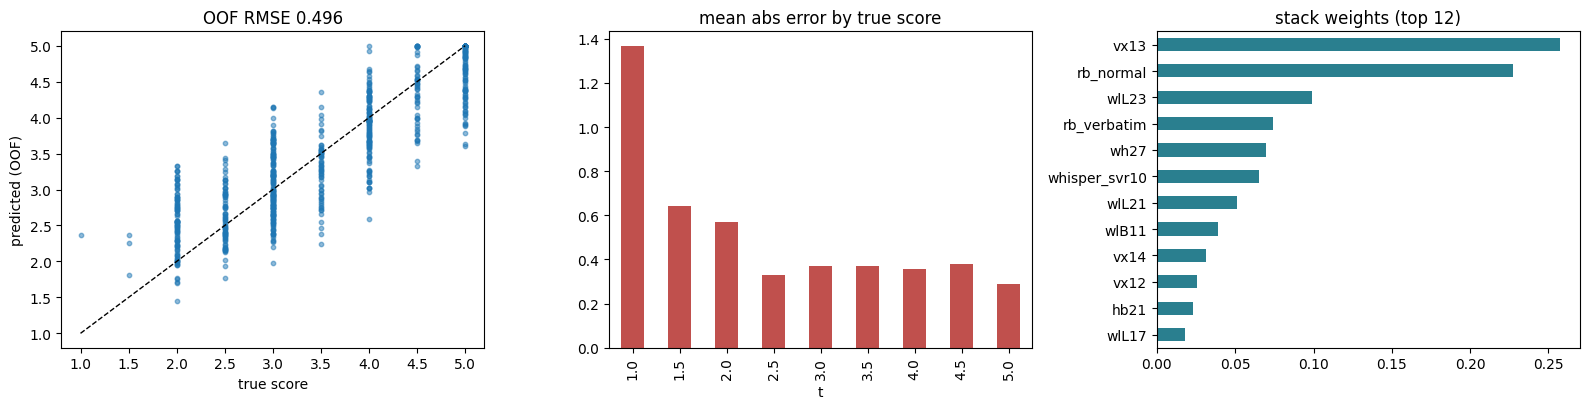

most correlated hand-made features:
 gec_edit_rate            -0.468
gec_changed_sent_ratio   -0.438
gec_edits                -0.339
n_words                   0.338
v_words                   0.312
v_ellipsis_rate          -0.273
n_sents                   0.270
avg_sent_len             -0.241


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(ym, oof_final, s=10, alpha=.5); ax[0].plot([1, 5], [1, 5], "k--", lw=1)
ax[0].set_xlabel("true score"); ax[0].set_ylabel("predicted (OOF)"); ax[0].set_title(f"OOF RMSE {rmse(ym, oof_final):.3f}")
pd.DataFrame({"t": ym, "e": np.abs(oof_final - ym)}).groupby("t")["e"].mean().plot.bar(ax=ax[1], color="#c0504d")
ax[1].set_title("mean abs error by true score")
top = pd.Series(w, index=names).sort_values(ascending=False)[:12]
top[::-1].plot.barh(ax=ax[2], color="#2a7f8f"); ax[2].set_title("stack weights (top 12)")
plt.tight_layout(); plt.show()
corr = pd.Series({c: pearsonr(hand[c].iloc[:n_tr].values[mk_], ym)[0] for c in hand.columns if hand[c].iloc[:n_tr].values[mk_].std() > 0})
print("most correlated hand-made features:\n", corr.reindex(corr.abs().sort_values(ascending=False).index)[:8].round(3).to_string())

## 12. Results

**Validation:** Speaker-grouped five-fold cross-validation on 732 scored clips gave RMSE 0.495 and Pearson correlation 0.873. Predictions on the training clips gave RMSE 0.297 and correlation 0.956.

**Leaderboard:** The reported public score was 0.3262 for the batch-specific, no-LoRA submission with zero-clip handling. This is an experimental submission variant; the main output is submission.csv.

## What helped

- Voxtral audio-token features were the strongest single feature view.
- Fine-tuning RoBERTa on verbatim transcripts improved the text models.
- Speaker-grouped validation tracked the leaderboard better than random folds.
- Layer-wise speech embeddings and prediction stacking improved the combined model.

## What helped less

The Qwen LoRA regressor had good cross-validation results but did not improve the public leaderboard. LLM rubric scores alone were also limited.

## Limits

The training set is small, and the public test set is smaller still. Small leaderboard differences may be noise. The model also makes larger errors at the low and high ends of the score range.

## AI tools

An AI coding assistant helped with implementation. The notebook contains the modeling steps and outputs.